# 08. 불만 토픽 — 무엇에 실망했나

**입력**: `dataSets/starfield_embeddings.npz`, `dataSets/starfield_analysis.csv`, `dataSets/reviews_for_embedding.csv`,
`dataSets/추천확률.csv` (05b), `dataSets/유저군집.csv` (06)
**출력**: `dataSets/불만토픽_v2.csv`, `out/08_*.png`

추천확률은 글이 **얼마나** 부정적인지는 재지만 **무엇이** 불만인지는 말하지 않는다.
그래서 글이 부정인 리뷰(추천확률 < 0.3)만 모아 임베딩 공간에서 군집화하고, 군집마다 자주 나오는 단어로 토픽을 읽는다.
그 토픽을 7장의 축(페르소나 · 진행 단계 · 불일치 케이스)에 올린다.

순서: ① 코퍼스 추출 → ② 언어·길이 성분 제거 → ③ K-Means(k=10) → ④ 특징어로 이름 붙이기 → ⑤ 페르소나·단계·케이스별 비교



In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from scipy.stats import chi2_contingency
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.metrics import silhouette_score
from sklearn.feature_extraction.text import CountVectorizer

RANDOM_STATE = 3217
NEG_THRESHOLD = 0.3    # 7장과 같은 "글이 부정" 기준
MIN_LEN = 20           # 이보다 짧은 글은 "무엇이" 불만인지가 없다 ("meh", "boring")
MIN_LANG_N = 20        # 리뷰가 이보다 적은 언어는 'other'로 묶는다
N_CLUSTERS = 10
os.makedirs('out', exist_ok=True)

# 한글 폰트: 폴더에 있는 폰트 파일을 쓰고, 없으면 맥 기본 폰트(AppleGothic)를 쓴다
FONT_FILE = 'helpers/fonts/NotoSansKR-Regular.ttf'
if os.path.exists(FONT_FILE):
    font_manager.fontManager.addfont(FONT_FILE)                                   # 폰트 파일 등록
    plt.rcParams['font.family'] = font_manager.FontProperties(fname=FONT_FILE).get_name()   # 파일 안의 폰트 이름을 읽어 지정
else:
    plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

PERSONAS = ['하드 리뷰어', '초기 리뷰어', '라이트 리뷰어']

## 1. 코퍼스 추출

원본 → 분석 대상 id → 임베딩 → 추천확률 → 페르소나 순으로 병합한다. 어느 단계에서든 행이 빠지면 멈춘다.

In [2]:
z = np.load('dataSets/starfield_embeddings.npz')
meta = pd.read_csv('dataSets/starfield_analysis.csv', low_memory=False)
pop = pd.read_csv('dataSets/reviews_for_embedding.csv', usecols=['steamid'])
prob = pd.read_csv('dataSets/추천확률.csv')
persona = pd.read_csv('dataSets/유저군집.csv')[['steamid', '군집']]

emb = pd.DataFrame({'steamid': z['steamid'], 'row': np.arange(len(z['steamid']))})

df = meta.merge(pop, on='steamid', how='inner')
df = df.merge(emb, on='steamid', how='inner')
df = df.merge(prob, on='steamid', how='inner')
df = df.merge(persona, on='steamid', how='inner')
df = df.reset_index(drop=True)
if len(df) != len(pop):
    raise ValueError('병합 중에 행이 빠졌다 — 03·05b·06을 다시 실행')

X = z['embeddings'].astype(np.float32)[df['row'].values]   # df 순서대로 벡터
df = df.drop(columns='row')
df['len'] = df['review'].str.len()
df['페르소나'] = df['군집'].map({'하드코어 리뷰어': '하드 리뷰어', '초반 리뷰어': '초기 리뷰어', '라이트 몰입형': '라이트 리뷰어'})
print('분석 모집단', len(df), '행')

분석 모집단 70915 행


In [3]:
is_neg_text = df['추천확률'] < NEG_THRESHOLD
keep = is_neg_text & (df['len'] >= MIN_LEN)

neg = df[keep].reset_index(drop=True)
X_neg = X[keep.values]

# 7장의 불일치 케이스 정의: 추천 버튼인데 글이 부정이면 '불일치 추천'
neg['케이스'] = '비추천'
neg.loc[neg['voted_up'] == True, '케이스'] = '불일치 추천'

print('글이 부정인 리뷰', is_neg_text.sum(), '건 중', MIN_LEN, '자 이상', len(neg), '건')
print(neg['케이스'].value_counts())

글이 부정인 리뷰 24434 건 중 20 자 이상 20924 건
케이스
비추천       19537
불일치 추천     1387
Name: count, dtype: int64


## 2. 언어·길이 성분 제거

임베딩을 그대로 군집화하면 토픽이 아니라 **어느 언어로, 얼마나 길게** 썼는지로 먼저 갈린다 (중국어 군집, 긴 영어 군집…).
그래서 "언어 더미 + log(길이)"로 각 벡터를 회귀하고, 설명되지 않은 **잔차**만 남긴다. 잔차 = 언어별 평균 벡터와 공통 길이 성분을 뺀 것.
그 뒤 길이가 1인 단위벡터로 만들어 코사인 거리로 군집화한다.

In [4]:
# 리뷰가 적은 언어는 'other'로 묶는다 (리뷰 1건인 언어는 평균 = 자기 자신이라 빼면 내용이 사라진다)
lang_count = neg['language'].map(neg['language'].value_counts())
lang_group = neg['language'].where(lang_count >= MIN_LANG_N, 'other')
print(MIN_LANG_N, '건 미만 언어 → other:', (lang_count < MIN_LANG_N).sum(), '건')

lang_dummies = pd.get_dummies(lang_group, dtype=np.float32).values      # 언어 더미 (n × 언어 수)
log_len = np.log1p(neg['len'].values.astype(np.float32)).reshape(-1, 1)  # log(길이) (n × 1)
design = np.hstack([lang_dummies, log_len])

# 더미가 절편 역할을 하므로 fit_intercept=False
reg = LinearRegression(fit_intercept=False).fit(design, X_neg)
X_adj = X_neg - reg.predict(design)                                    # 잔차

norms = np.linalg.norm(X_adj, axis=1, keepdims=True)
X_adj = X_adj / np.maximum(norms, 1e-9)                                 # 단위벡터로

20 건 미만 언어 → other: 57 건


In [5]:
# 보정이 언어 정보를 실제로 지웠는지 확인: 보정 후 벡터로 언어를 맞히는 정확도가
# "최빈 언어만 찍는 수준"까지 떨어지면 성공
top5 = neg['language'].value_counts().index[:5]
probe_idx = np.where(neg['language'].isin(top5).values)[0]
probe_idx = np.random.RandomState(RANDOM_STATE).choice(probe_idx, 6000, replace=False)
probe_y = neg['language'].values[probe_idx]
majority = pd.Series(probe_y).value_counts(normalize=True).iloc[0]

for name, M in [('원본', X_neg), ('보정 후', X_adj)]:
    acc = cross_val_score(LogisticRegression(max_iter=200), M[probe_idx], probe_y, cv=3).mean()
    print(f'{name:<6} 언어 분류 정확도 {acc:.3f}')
print(f'(참고) 최빈 언어만 찍었을 때 {majority:.3f}')

원본     언어 분류 정확도 0.962
보정 후   언어 분류 정확도 0.751
(참고) 최빈 언어만 찍었을 때 0.751


## 3. 군집 수 확인과 K-Means

실루엣은 k 4~15 전 구간에서 0.04로 거의 평평하다 — 같은 게임의 불만은 경계 없는 연속체다.
그래서 실루엣이 아니라 "읽을 수 있는 토픽 수"로 k=10을 쓴다.

In [6]:
sample = np.random.RandomState(RANDOM_STATE).choice(len(X_adj), 3000, replace=False)
X_sample = X_adj[sample]
for k in range(4, 16):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=5).fit(X_sample)
    sil = silhouette_score(X_sample, km.labels_, metric='cosine')
    print(f'k={k:<3} 실루엣 {sil:.4f}')

k=4   실루엣 0.0383
k=5   실루엣 0.0367
k=6   실루엣 0.0359
k=7   실루엣 0.0371
k=8   실루엣 0.0378
k=9   실루엣 0.0382
k=10  실루엣 0.0381
k=11  실루엣 0.0374
k=12  실루엣 0.0381
k=13  실루엣 0.0373
k=14  실루엣 0.0395
k=15  실루엣 0.0376


In [7]:
km = KMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_STATE, n_init=10).fit(X_adj)
neg['cluster'] = km.labels_

# 군집마다 언어 비율이 전체(영어 약 60%)와 비슷하면 언어로 갈리지 않은 것
mix = neg.groupby('cluster').agg(
    n=('cluster', 'size'),
    영어비율=('language', lambda s: (s == 'english').mean() * 100),
    중국어비율=('language', lambda s: (s == 'schinese').mean() * 100),
    중앙길이=('len', 'median'),
    불일치추천비율=('voted_up', lambda s: s.mean() * 100),
)
print('전체 영어 비율', round((neg['language'] == 'english').mean() * 100), '%')
print(mix.round(1))

전체 영어 비율 70 %
            n  영어비율  중국어비율   중앙길이  불일치추천비율
cluster                                   
0        1603  81.5    2.2  616.0      5.6
1        1906  61.8   23.0   79.0      5.1
2        2820  65.1   19.7  292.0      5.8
3        1495  65.8   19.6  191.0      8.6
4        1475  75.0    9.2  201.0      4.9
5        1250  80.9    5.8  237.0      4.6
6        3026  75.8   10.4  223.0      4.0
7        2648  69.3   15.7  163.0      6.5
8        1553  57.8   26.7  206.0      8.4
9        3148  70.6   15.6  189.0     11.3


## 4. 군집별 특징어(c-TF-IDF)와 이름

군집 하나를 문서 하나로 합쳐서 TF-IDF를 계산하면 그 군집에서만 유독 많이 쓰인 단어가 뜬다.
여러 언어가 섞이면 읽기 어려우므로 영어 리뷰만으로 특징어를 뽑는다.

In [8]:
STOP = {'game', 'games', 'just', 'like', 'starfield', 'bethesda', 'play', 'playing', 'really'}


def top_terms_by_cluster(labels, n_terms=8):
    """군집 번호 → 특징어 리스트. 영어 리뷰만 사용."""
    n_clusters = labels.max() + 1
    is_english = (neg['language'] == 'english').values

    # 군집마다 영어 리뷰를 한 덩어리 문서로 합친다
    docs = []
    for c in range(n_clusters):
        texts = neg['review'][is_english & (labels == c)]
        docs.append(' '.join(texts))

    vec = CountVectorizer(stop_words='english', ngram_range=(1, 2), min_df=2)
    counts = vec.fit_transform(docs).toarray().astype(float)   # (군집 수 × 단어 수)
    vocab = np.array(vec.get_feature_names_out())

    tf = counts / np.maximum(counts.sum(axis=1, keepdims=True), 1)                      # 군집 안에서의 비율
    idf = np.log(1 + counts.sum(axis=1).mean() / np.maximum(counts.sum(axis=0), 1))     # 전체에서 흔한 단어는 낮게
    c_tfidf = tf * idf

    result = {}
    for c in range(n_clusters):
        order = np.argsort(-c_tfidf[c])        # 점수 높은 순
        words = []
        for i in order[:40]:
            if vocab[i] not in STOP:
                words.append(vocab[i])
        result[c] = words[:n_terms]
    return result


top_terms = top_terms_by_cluster(neg['cluster'].values)
for c, terms in top_terms.items():
    print(f'{c:>2}  {", ".join(terms)}')

 0  fallout, space, time, skyrim, story, good, feels, boring
 1  ship, space, time, boring, don, planet, good, bad
 2  space, boring, planets, ship, story, travel, fallout, exploration
 3  bugs, hours, fix, bug, save, ship, crashes, time
 4  mods, paid, paid mods, modders, mod, community, fix, creation
 5  loading, screen, screens, loading screens, loading screen, simulator, space, planet
 6  fallout, boring, bethesda game, skyrim, story, good, time, elder
 7  boring, hours, story, time, feels, good, fun, don
 8  pc, performance, fps, settings, run, runs, dlss, better
 9  space, ship, time, fallout, don, make, good, story


In [9]:
# 군집마다 중간 길이의 영어 리뷰 3건을 읽어 본다 (이름 붙일 때 참고)
rng = np.random.RandomState(RANDOM_STATE)
for c in range(N_CLUSTERS):
    pool = neg.index[(neg['cluster'] == c) & (neg['language'] == 'english') & neg['len'].between(60, 200)]
    print()
    print('[군집', c, ']', ', '.join(top_terms[c][:5]))
    for i in rng.choice(pool, 3, replace=False):
        print('  -', neg['review'][i][:160].replace('\n', ' '))


[군집 0 ] fallout, space, time, skyrim, story
  - starefield.... gameplay is boring, nothing that stands out. Most of the game is repetitive missions and dialog
  - Starfield is the definition of unfunny. Gameplay is so boring i couldn't drag myself to keep playing it to see if something interesting happened
  - Creations need to go, especially in a game as threadbare here. Starfield has nice gameplay, but if they're going to price gouge drip fed content it's not worth 

[군집 1 ] ship, space, time, boring, don
  - not really worth the time or coin to play this game the studio and publisher should be ashamed
  - Soulless empty game which promises a lot but does not live up to a single expectation.
  - It's below everyone's expectations and not worth the extremely high price

[군집 2 ] space, boring, planets, ship, story
  - hope you enjoy pressing a button to fast travel between planets because they forgot to implement any meaningful space ship travel in this space ship game
  - Exploration

이름은 특징어와 대표 리뷰를 읽고 사람이 붙였다. 다만 군집 **번호**는 실행 환경에 따라 바뀔 수 있어서 번호에 이름을 직접 쓰지 않고,
각 토픽을 알아보는 단어(앵커)가 특징어 상위에 가장 먼저 나오는 군집에 그 이름을 준다.
앵커가 없는 나머지 4개 군집은 글 길이(가장 짧음 → 단문 혹평, 가장 김 → 장문 종합비판)와 추천 버튼 비율(가장 높음 → 유머·냉소·잡담)로 가른다.

In [10]:
ANCHOR_WORDS = {'성능·최적화': 'fps', '로딩화면': 'loading', '버그·크래시': 'bug', '유료 모드·DLC': 'mods',
                '베데스다 답습': 'elder', '우주탐험 빈약': 'planets'}

terms40 = top_terms_by_cluster(neg['cluster'].values, n_terms=40)


def rank_of_word(word, terms):
    """특징어 리스트에서 word가 포함된 첫 위치. 없으면 99"""
    for r, t in enumerate(terms):
        if word in t:
            return r
    return 99


cluster_names = {}
for name, word in ANCHOR_WORDS.items():
    best_cluster = None
    best_rank = 99
    for c, terms in terms40.items():
        r = rank_of_word(word, terms)
        if r < best_rank:
            best_rank = r
            best_cluster = c
    if best_cluster is None or best_cluster in cluster_names:
        raise ValueError(f'{name}: 앵커 {word}로 군집을 찾지 못했거나 다른 이름과 겹침 — 특징어를 다시 읽을 것')
    cluster_names[best_cluster] = name

# 나머지 4개 군집
median_len = neg.groupby('cluster')['len'].median()
thumbs_up_rate = neg.groupby('cluster')['voted_up'].mean()
rest = [c for c in range(N_CLUSTERS) if c not in cluster_names]

shortest = median_len[rest].idxmin()
longest = median_len[rest].idxmax()
cluster_names[shortest] = '단문 혹평'
cluster_names[longest] = '장문 종합비판'

rest = [c for c in rest if c not in cluster_names]
humor = thumbs_up_rate[rest].idxmax()
cluster_names[humor] = '유머·냉소·잡담'

rest = [c for c in rest if c not in cluster_names]
cluster_names[rest[0]] = '지루함·퀘스트'

check = pd.DataFrame({
    '이름': pd.Series(cluster_names),
    '중앙길이': median_len,
    '불일치추천(%)': thumbs_up_rate * 100,
    '특징어': pd.Series({c: ', '.join(t[:5]) for c, t in top_terms.items()}),
})
print('군집 번호 → 이름 (특징어·길이·비율이 이름과 맞는지 눈으로 확인)')
print(check.round(1))

neg['토픽'] = neg['cluster'].map(cluster_names)

군집 번호 → 이름 (특징어·길이·비율이 이름과 맞는지 눈으로 확인)
          이름   중앙길이  불일치추천(%)  \
0    장문 종합비판  616.0       5.6   
1      단문 혹평   79.0       5.1   
2    우주탐험 빈약  292.0       5.8   
3     버그·크래시  191.0       8.6   
4  유료 모드·DLC  201.0       4.9   
5       로딩화면  237.0       4.6   
6    베데스다 답습  223.0       4.0   
7    지루함·퀘스트  163.0       6.5   
8     성능·최적화  206.0       8.4   
9   유머·냉소·잡담  189.0      11.3   

                                                 특징어  
0                fallout, space, time, skyrim, story  
1                     ship, space, time, boring, don  
2                space, boring, planets, ship, story  
3                        bugs, hours, fix, bug, save  
4                mods, paid, paid mods, modders, mod  
5  loading, screen, screens, loading screens, loa...  
6      fallout, boring, bethesda game, skyrim, story  
7                  boring, hours, story, time, feels  
8                pc, performance, fps, settings, run  
9                    space, ship, time, fallout

In [11]:
TECH = ['성능·최적화', '버그·크래시', '로딩화면', '유료 모드·DLC']   # 기술·운영 불만 (뚜렷한 토픽)
NAMED = ['베데스다 답습', '우주탐험 빈약']                          # 뚜렷한 콘텐츠 불만
GENERAL = ['지루함·퀘스트', '단문 혹평', '장문 종합비판', '유머·냉소·잡담']   # 형식으로 갈린 콘텐츠 일반
TOPIC_ORDER = TECH + NAMED + GENERAL
TOPIC_COLOR = {}
for t in TECH:
    TOPIC_COLOR[t] = '#c44e52'
for t in NAMED:
    TOPIC_COLOR[t] = '#4c72b0'
for t in GENERAL:
    TOPIC_COLOR[t] = '#9a9a9a'

neg['구간'] = pd.cut(neg['stage_at_review'], [-1, 1, 2, 4, 9, 10], labels=['0~1 초반', '2 이탈구간', '3~4', '5~9', '10 완주'])

summary = neg.groupby('토픽').agg(
    n=('토픽', 'size'),
    리뷰시점_플레이분=('playtime_at_review_min', 'median'),
    불일치추천비율=('voted_up', 'mean'),
).loc[TOPIC_ORDER]
summary['구성비(%)'] = summary['n'] / len(neg) * 100
summary['리뷰시점_플레이h'] = summary['리뷰시점_플레이분'] / 60
summary['불일치추천비율'] = summary['불일치추천비율'] * 100
print(summary[['n', '구성비(%)', '리뷰시점_플레이h', '불일치추천비율']].round(1))

              n  구성비(%)  리뷰시점_플레이h  불일치추천비율
토픽                                         
성능·최적화     1553     7.4        9.9      8.4
버그·크래시     1495     7.1       39.6      8.6
로딩화면       1250     6.0       31.2      4.6
유료 모드·DLC  1475     7.0       61.5      4.9
베데스다 답습    3026    14.5       39.2      4.0
우주탐험 빈약    2820    13.5       34.4      5.8
지루함·퀘스트    2648    12.7       36.9      6.5
단문 혹평      1906     9.1       35.1      5.1
장문 종합비판    1603     7.7       47.0      5.6
유머·냉소·잡담   3148    15.0       42.8     11.3


## 5. 핵심 결과 ①: 페르소나별 불만 토픽

페르소나별 토픽 구성비(%)를 전체 구성비와 비교해 %p 차이로 읽는다.

In [12]:
share_all = neg['토픽'].value_counts(normalize=True) * 100                        # 전체 구성비
comp_persona = pd.crosstab(neg['토픽'], neg['페르소나'], normalize='columns') * 100   # 페르소나별 구성비
comp_persona = comp_persona.loc[TOPIC_ORDER, PERSONAS]
print('페르소나별 토픽 구성비 (%)')
print(comp_persona.round(1))

diff_persona = comp_persona.copy()
for p in PERSONAS:
    diff_persona[p] = comp_persona[p] - share_all[TOPIC_ORDER]
print()
print('전체 대비 차이 (%p)')
print(diff_persona.round(1))

# 카이제곱 검정과 효과크기(Cramér's V). 표본이 크면 p는 쉽게 작아지므로 V를 같이 본다
table = pd.crosstab(neg['페르소나'], neg['토픽'])
chi2, p, dof, expected = chi2_contingency(table)
v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
print()
print(f"토픽 × 페르소나: chi2 = {chi2:.1f}, p = {p:.1e}, Cramér's V = {v:.3f}")

페르소나별 토픽 구성비 (%)
페르소나       하드 리뷰어  초기 리뷰어  라이트 리뷰어
토픽                                
성능·최적화        3.5    14.0      4.9
버그·크래시        5.9     7.2      8.9
로딩화면          5.2     6.6      6.2
유료 모드·DLC     9.4     4.6      6.7
베데스다 답습      15.5    13.3     14.4
우주탐험 빈약      13.1    13.6     13.9
지루함·퀘스트      11.9    12.5     13.9
단문 혹평         9.1     9.2      9.0
장문 종합비판       9.4     5.8      7.5
유머·냉소·잡담     17.1    13.2     14.5

전체 대비 차이 (%p)
페르소나       하드 리뷰어  초기 리뷰어  라이트 리뷰어
토픽                                
성능·최적화       -3.9     6.6     -2.5
버그·크래시       -1.3     0.0      1.7
로딩화면         -0.8     0.7      0.3
유료 모드·DLC     2.4    -2.4     -0.3
베데스다 답습       1.0    -1.1     -0.0
우주탐험 빈약      -0.4     0.1      0.5
지루함·퀘스트      -0.8    -0.1      1.3
단문 혹평         0.0     0.1     -0.1
장문 종합비판       1.8    -1.9     -0.2
유머·냉소·잡담      2.0    -1.9     -0.6

토픽 × 페르소나: chi2 = 944.6, p = 4.8e-189, Cramér's V = 0.150


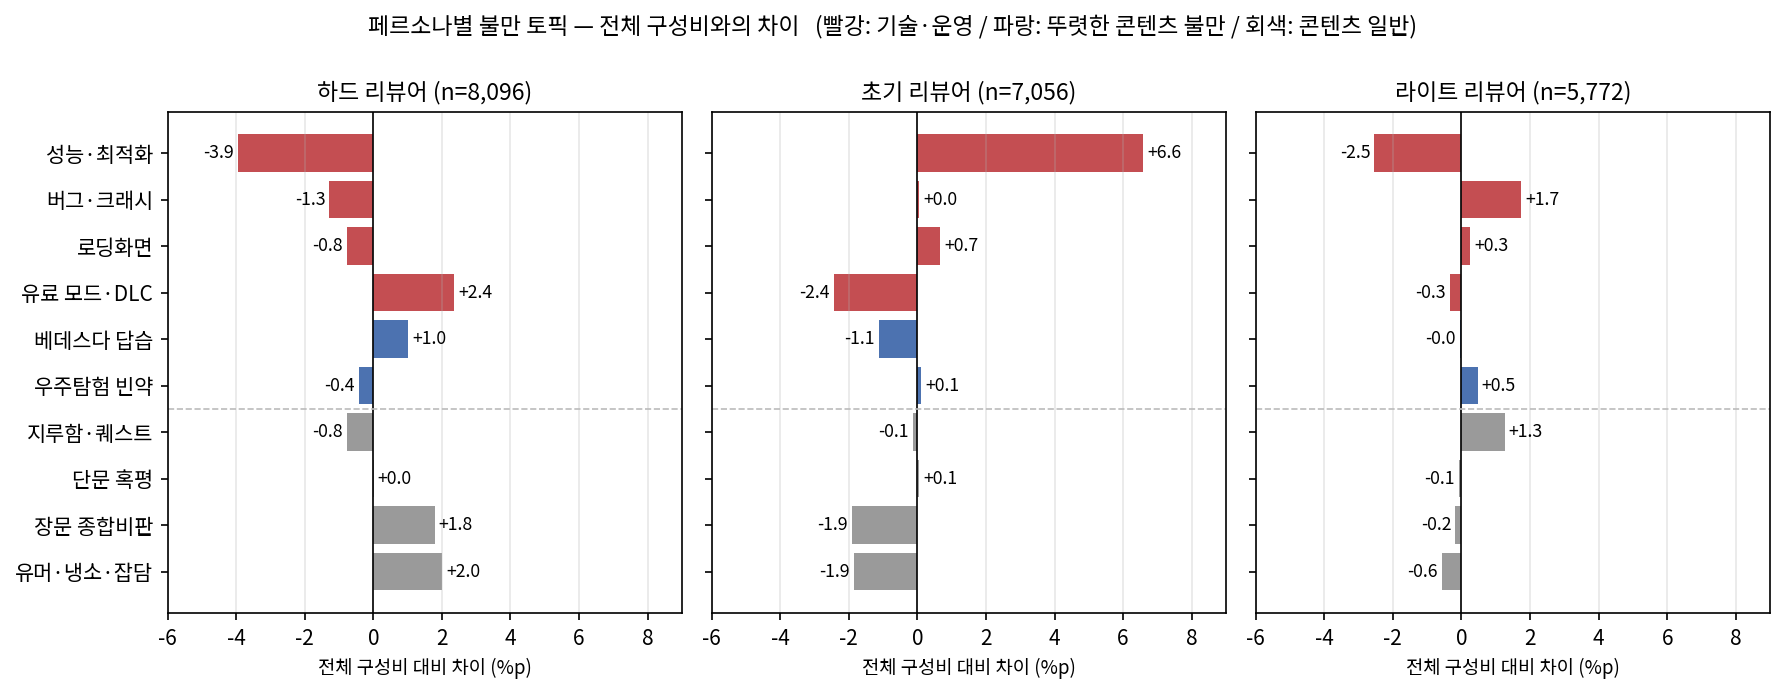

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.6), dpi=150, sharey=True)
for ax, name in zip(axes, PERSONAS):
    d = diff_persona[name].loc[TOPIC_ORDER[::-1]]       # 큰 토픽이 위로
    colors = [TOPIC_COLOR[t] for t in d.index]
    bars = ax.barh(d.index, d.values, color=colors)
    ax.axvline(0, color='black', lw=0.8)
    ax.axhline(3.5, color='#bbbbbb', lw=0.8, ls='--')   # 뚜렷한 토픽 6개와 콘텐츠 일반 4개 사이
    ax.bar_label(bars, fmt='%+.1f', fontsize=8.5, padding=2)
    n_p = (neg['페르소나'] == name).sum()
    ax.set_title(f'{name} (n={n_p:,})', fontsize=11)
    ax.set_xlim(-6, 9)
    ax.set_xlabel('전체 구성비 대비 차이 (%p)', fontsize=9)
    ax.grid(axis='x', alpha=0.3)
fig.suptitle('페르소나별 불만 토픽 — 전체 구성비와의 차이   (빨강: 기술·운영 / 파랑: 뚜렷한 콘텐츠 불만 / 회색: 콘텐츠 일반)', fontsize=11, y=0.995)
fig.tight_layout()
fig.savefig('out/08_ppt_토픽_페르소나_차이.png', bbox_inches='tight')
plt.show()

콘텐츠 불만(파랑·회색)은 세 페르소나에서 비중 차이가 ±2%p 안이다. 차이는 기술·운영 불만(빨강)에서 난다:
초기 리뷰어는 **성능·최적화**가 전체의 두 배, 하드 리뷰어는 **유료 모드·DLC**, 라이트 리뷰어는 **버그·크래시**.

## 6. 핵심 결과 ②: 진행 단계별 불만 토픽

In [14]:
comp_stage = pd.crosstab(neg['구간'], neg['토픽'], normalize='index') * 100
comp_stage = comp_stage[TOPIC_ORDER]
print('구간별 n:', neg['구간'].value_counts().sort_index().to_dict())
print(comp_stage.round(1).T)

# 초기 리뷰어의 성능 불만이 "일찍 써서"만은 아닌지: 같은 2단계 리뷰 안에서 페르소나별 성능 비율 비교
stage2 = neg[neg['stage_at_review'] == 2]
print()
print('stage 2 리뷰만 — 페르소나별 성능·최적화 비율 (%)')
for name in PERSONAS:
    g = stage2[stage2['페르소나'] == name]
    print(f'  {name:<8} {(g["토픽"] == "성능·최적화").mean() * 100:.1f}%  (n={len(g):,})')

구간별 n: {'0~1 초반': 2327, '2 이탈구간': 9196, '3~4': 3009, '5~9': 2691, '10 완주': 3701}
구간         0~1 초반  2 이탈구간   3~4   5~9  10 완주
토픽                                          
성능·최적화       18.9     8.6   4.5   3.0    2.8
버그·크래시       10.4     7.1   6.5   8.7    4.6
로딩화면          4.3     6.9   6.1   5.2    5.2
유료 모드·DLC     5.6     5.9   6.9   8.1   10.2
베데스다 답습      12.0    14.8  14.9  14.1   15.1
우주탐험 빈약      11.4    13.7  14.1  13.6   13.5
지루함·퀘스트      10.5    12.4  12.8  15.1   12.8
단문 혹평         7.1     9.5   9.2   9.4    9.1
장문 종합비판       5.4     6.9   8.8   8.7    9.4
유머·냉소·잡담     14.4    14.2  16.2  14.2   17.3

stage 2 리뷰만 — 페르소나별 성능·최적화 비율 (%)
  하드 리뷰어   4.9%  (n=2,645)
  초기 리뷰어   11.6%  (n=4,681)
  라이트 리뷰어  6.4%  (n=1,870)


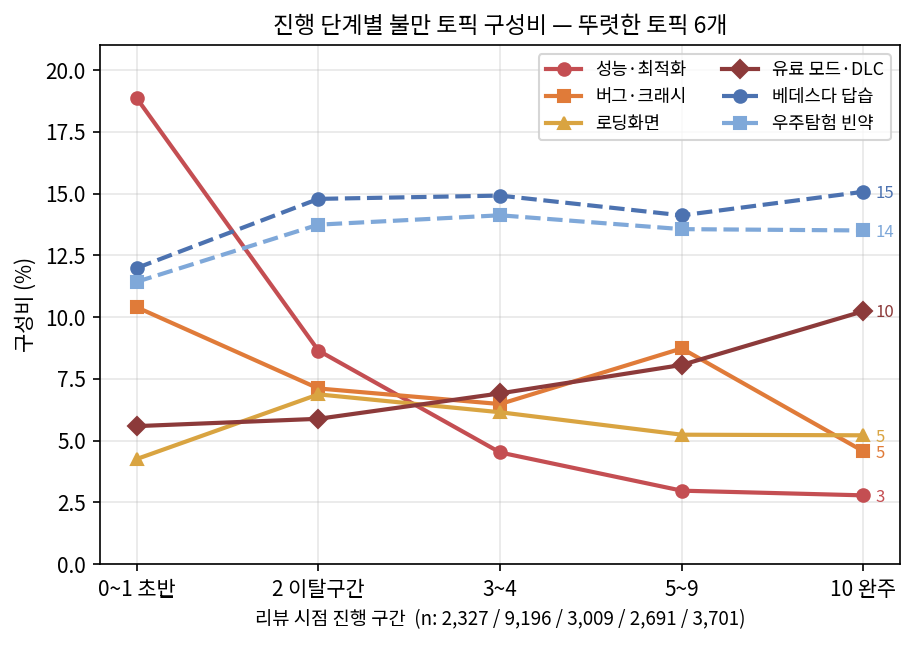

In [15]:
# 뚜렷한 토픽 6개의 단계별 구성비 선그래프
STYLE = {'성능·최적화': ('#c44e52', '-', 'o'), '버그·크래시': ('#e07b39', '-', 's'), '로딩화면': ('#d9a441', '-', '^'),
         '유료 모드·DLC': ('#8c3a3a', '-', 'D'), '베데스다 답습': ('#4c72b0', '--', 'o'), '우주탐험 빈약': ('#7fa8d9', '--', 's')}
bins = list(comp_stage.index.astype(str))

fig, ax = plt.subplots(figsize=(6.2, 4.4), dpi=150)
for topic, (color, ls, marker) in STYLE.items():
    values = comp_stage[topic].values
    ax.plot(bins, values, color=color, ls=ls, marker=marker, lw=2, label=topic)
    ax.annotate(f'{values[-1]:.0f}', (len(bins) - 1, values[-1]), textcoords='offset points', xytext=(6, -3), fontsize=8, color=color)
n_bins = neg['구간'].value_counts().reindex(comp_stage.index)
ax.set_ylabel('구성비 (%)')
ax.set_xlabel('리뷰 시점 진행 구간  (n: ' + ' / '.join(f'{v:,}' for v in n_bins) + ')', fontsize=9)
ax.set_ylim(0, 21)
ax.grid(alpha=0.3)
ax.legend(fontsize=8.5, ncol=2, loc='upper right')
ax.set_title('진행 단계별 불만 토픽 구성비 — 뚜렷한 토픽 6개', fontsize=11)
fig.tight_layout()
fig.savefig('out/08_ppt_단계별_토픽구성비.png', bbox_inches='tight')
plt.show()

## 7. 핵심 결과 ③: 불일치 추천은 무엇을 쓰나

추천 버튼을 누르고도 부정적인 글을 쓴 리뷰(불일치 추천)가 비추천 리뷰와 같은 불만을 쓰는지 비교한다.

{'비추천': 19537, '불일치 추천': 1387}
케이스        불일치 추천   비추천  차이(%p)
토픽                             
유머·냉소·잡담     25.7  14.3    11.4
버그·크래시        9.3   7.0     2.3
성능·최적화        9.4   7.3     2.1
지루함·퀘스트      12.3  12.7    -0.3
장문 종합비판       6.4   7.7    -1.3
우주탐험 빈약      11.8  13.6    -1.8
로딩화면          4.2   6.1    -1.9
유료 모드·DLC     5.3   7.2    -1.9
단문 혹평         7.1   9.3    -2.2
베데스다 답습       8.7  14.9    -6.2


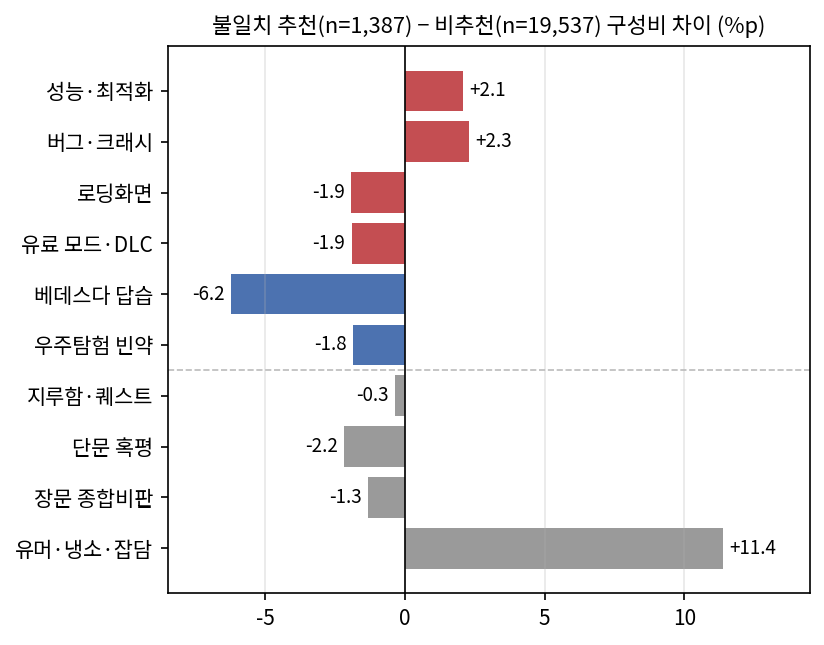

In [16]:
comp_case = pd.crosstab(neg['토픽'], neg['케이스'], normalize='columns') * 100
comp_case = comp_case.loc[TOPIC_ORDER]
comp_case['차이(%p)'] = comp_case['불일치 추천'] - comp_case['비추천']
print(neg['케이스'].value_counts().to_dict())
print(comp_case.round(1).sort_values('차이(%p)', ascending=False))

n_mis = (neg['케이스'] == '불일치 추천').sum()
n_neg = (neg['케이스'] == '비추천').sum()
d = comp_case['차이(%p)'].loc[TOPIC_ORDER[::-1]]

fig, ax = plt.subplots(figsize=(5.6, 4.4), dpi=150)
bars = ax.barh(d.index, d.values, color=[TOPIC_COLOR[t] for t in d.index])
ax.axvline(0, color='black', lw=0.8)
ax.axhline(3.5, color='#bbbbbb', lw=0.8, ls='--')
ax.bar_label(bars, fmt='%+.1f', fontsize=9, padding=3)
ax.set_xlim(-8.5, 14.5)
ax.grid(axis='x', alpha=0.3)
ax.set_title(f'불일치 추천(n={n_mis:,}) − 비추천(n={n_neg:,}) 구성비 차이 (%p)', fontsize=10.5)
fig.tight_layout()
fig.savefig('out/08_ppt_불일치추천_vs_비추천.png', bbox_inches='tight')
plt.show()

In [17]:
# 불일치 추천에서 가장 많이 늘어나는 '유머·냉소·잡담'을 직접 읽어 본다
rng = np.random.RandomState(RANDOM_STATE)
pool = neg.index[(neg['토픽'] == '유머·냉소·잡담') & (neg['케이스'] == '불일치 추천')
                 & (neg['language'] == 'english') & neg['len'].between(40, 300)]
print('유머·냉소·잡담 × 불일치 추천 (영어 40~300자', len(pool), '건 중 무작위 12건)')
for i in rng.choice(pool, 12, replace=False):
    print('  -', neg['review'][i][:200].replace('\n', ' '))

유머·냉소·잡담 × 불일치 추천 (영어 40~300자 63 건 중 무작위 12건)
  - This game makes me want to say the N word.
  - "you see that planet? you can't climb it" - todd howard
  - The negative reviews are from PS5 owners.
  - Todd threatened to space me out an airlock unless I gave a good review.
  - No one is Going to read this review so i want to confess that i am gay .
  - started game, ignored main quest, a guard told me that the vanguard where looking for recruits ended up fighting for my life against space deathclaws whiles dealing with interstellar politics between 
  - please help, my inventory full of useless stuffs.
  - if you have bring up baldur's gate when talking about this game you're an insecure little weirdo
  - 10 OUDDA 10 NOW PREVIOUSLY NOT 10 OUDDA 10
  - I spend 3 hours figuring out how to get a bounty off my head for picking up a contraband painting and paid more credits to get the bounty off my head then the paintings were worth... noted do not pick
  - Once again proved IGN is nothing

불일치 추천의 상당 부분은 "추천하지만 X는 싫다"는 조건부 불만과 농담·반어로 쓴 글이다. 분류기는 문장의 감성을 읽으므로 반어는 부정으로 판정된다.
그래서 불일치 추천을 "개선 요구가 담긴 추천"으로 읽을 때는 유머·냉소 군집을 걷어낸 나머지(성능·버그 등 기술 불만이 비추천보다 높은 부분)를 근거로 삼아야 한다.

## 8. 저장

In [18]:
neg[['steamid', 'cluster', '토픽', '페르소나', '케이스', 'stage_at_review', '구간', 'voted_up', '추천확률', 'language']].to_csv('dataSets/불만토픽_v2.csv', index=False)
print('저장 완료: dataSets/불만토픽_v2.csv (', len(neg), '행 )')

저장 완료: dataSets/불만토픽_v2.csv ( 20924 행 )
